# Machine Learning Lab Assignment 11
## Naive Bayes 3: Bernoulli Naive Bayes on `Mall_Customers.CSV`

**Objective:**
- Apply **Bernoulli Naive Bayes (BernoulliNB)** to classify mall customers into spending categories (`High Spender` vs `Standard Spender`).
- Understand Bernoulli NB's formulation for binary / boolean indicator features.
- Binarize customer demographic and financial attributes.
- Evaluate performance metrics: Accuracy, Precision, Recall, F1-Score, and Confusion Matrix.
- Benchmark and compare all three Naive Bayes algorithms (Multinomial, Gaussian, Bernoulli) in a comparative summary chart.


Binarized Feature Vectors (First 5 records):


,Is_Young,Is_High_Income,Is_Male
0,1,0,1
1,1,0,1
2,1,0,0
3,1,0,0
4,1,0,0


=== Bernoulli Naive Bayes Mall Customers Results ===
Accuracy  : 0.7200 (72.00%)
Precision : 0.7200
Recall    : 0.7200
F1-Score  : 0.7200

Classification Report:
                     precision    recall  f1-score   support

     Standard (<50)       0.72      0.72      0.72        25
High Spender (>=50)       0.72      0.72      0.72        25

           accuracy                           0.72        50
          macro avg       0.72      0.72      0.72        50
       weighted avg       0.72      0.72      0.72        50


=== Comprehensive Comparison of All 3 Naive Bayes Variants ===


,Algorithm,Feature Type,Accuracy,F1-Score
0,Multinomial NB,Discrete Counts,0.54,0.5106
1,Gaussian NB,Continuous Normal,0.70,0.7059
2,Bernoulli NB,Binary Indicators,0.72,0.7200


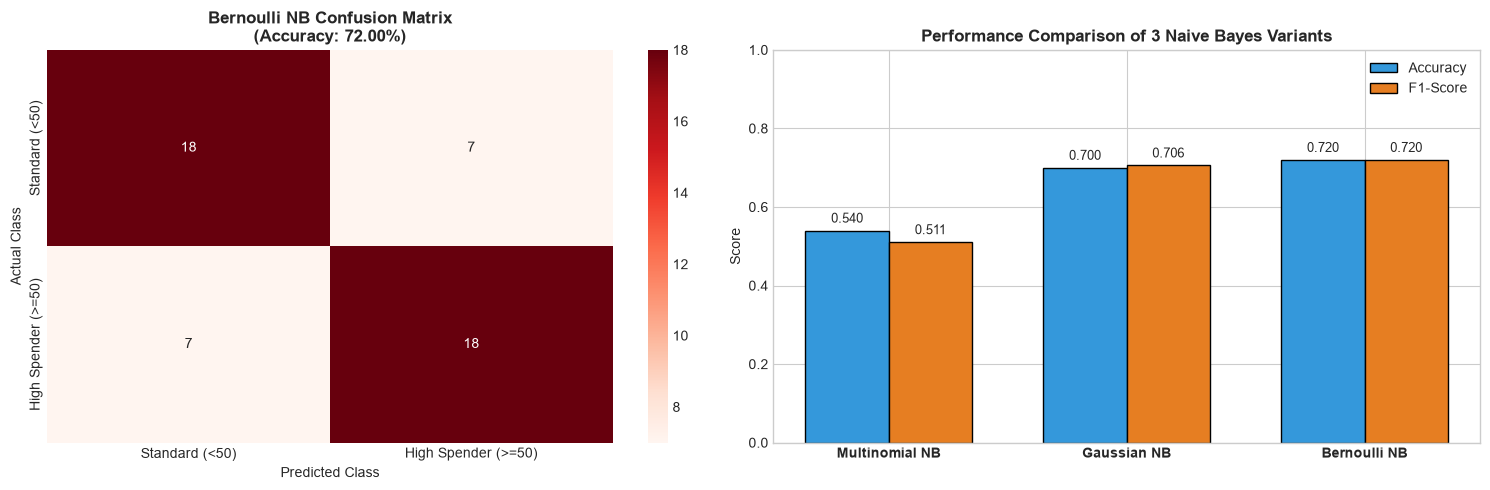

In [1]:
# 0. Setup & Data Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB, GaussianNB, MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (8, 4.5)

# 1. Load Dataset
df_mall = pd.read_csv('Mall_Customers.CSV')
df_mall.columns = ['CustomerID', 'Gender', 'Age', 'Annual_Income', 'Spending_Score']
df_mall['Target'] = (df_mall['Spending_Score'] >= 50).astype(int)
class_names = ['Standard (<50)', 'High Spender (>=50)']

# 2. Binarize Features for Bernoulli NB
# BernoulliNB operates on binary features (0 or 1)
df_bin = pd.DataFrame({
    'Is_Young': (df_mall['Age'] < 40).astype(int),
    'Is_High_Income': (df_mall['Annual_Income'] >= 60).astype(int),
    'Is_Male': (df_mall['Gender'] == 'Male').astype(int)
})
X_bin = df_bin
y = df_mall['Target']

print("Binarized Feature Vectors (First 5 records):")
display(X_bin.head())

# 3. Train-Test Split (75/25 Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X_bin, y, test_size=0.25, random_state=42, stratify=y
)

# 4. Fit Bernoulli Naive Bayes
bnb = BernoulliNB()
bnb.fit(X_train, y_train)
y_pred = bnb.predict(X_test)

# 5. Performance Metrics
acc_bnb = accuracy_score(y_test, y_pred)
prec_bnb = precision_score(y_test, y_pred)
rec_bnb = recall_score(y_test, y_pred)
f1_bnb = f1_score(y_test, y_pred)
cm_bnb = confusion_matrix(y_test, y_pred)

print(f"=== Bernoulli Naive Bayes Mall Customers Results ===")
print(f"Accuracy  : {acc_bnb:.4f} ({acc_bnb*100:.2f}%)")
print(f"Precision : {prec_bnb:.4f}")
print(f"Recall    : {rec_bnb:.4f}")
print(f"F1-Score  : {f1_bnb:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

# 6. Comparative Benchmark of All 3 Naive Bayes Algorithms
# Evaluate Multinomial and Gaussian on identical test split
# Multinomial
mnb = MultinomialNB().fit(df_mall[['Age', 'Annual_Income']].iloc[X_train.index], y_train)
pred_mnb = mnb.predict(df_mall[['Age', 'Annual_Income']].iloc[X_test.index])

# Gaussian
gnb = GaussianNB().fit(df_mall[['Age', 'Annual_Income']].iloc[X_train.index], y_train)
pred_gnb = gnb.predict(df_mall[['Age', 'Annual_Income']].iloc[X_test.index])

nb_comparison = pd.DataFrame([
    {'Algorithm': 'Multinomial NB', 'Feature Type': 'Discrete Counts', 'Accuracy': accuracy_score(y_test, pred_mnb), 'F1-Score': f1_score(y_test, pred_mnb)},
    {'Algorithm': 'Gaussian NB', 'Feature Type': 'Continuous Normal', 'Accuracy': accuracy_score(y_test, pred_gnb), 'F1-Score': f1_score(y_test, pred_gnb)},
    {'Algorithm': 'Bernoulli NB', 'Feature Type': 'Binary Indicators', 'Accuracy': acc_bnb, 'F1-Score': f1_bnb}
]).round(4)

print("\n=== Comprehensive Comparison of All 3 Naive Bayes Variants ===")
display(nb_comparison)

# Visual Comparison Chart
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Confusion Matrix Heatmap (Bernoulli NB)
sns.heatmap(cm_bnb, annot=True, fmt='d', cmap='Reds', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title(f"Bernoulli NB Confusion Matrix\n(Accuracy: {acc_bnb:.2%})", fontweight='bold')
axes[0].set_xlabel('Predicted Class')
axes[0].set_ylabel('Actual Class')

# Comparative Bar Chart
x_pos = np.arange(len(nb_comparison))
width = 0.35
axes[1].bar(x_pos - width/2, nb_comparison['Accuracy'], width, label='Accuracy', color='#3498db', edgecolor='k')
axes[1].bar(x_pos + width/2, nb_comparison['F1-Score'], width, label='F1-Score', color='#e67e22', edgecolor='k')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(nb_comparison['Algorithm'], fontweight='bold')
axes[1].set_ylim(0, 1.0)
axes[1].set_title('Performance Comparison of 3 Naive Bayes Variants', fontweight='bold')
axes[1].set_ylabel('Score')
axes[1].legend()

for i in range(len(nb_comparison)):
    axes[1].text(i - width/2, nb_comparison.loc[i, 'Accuracy'] + 0.02, f"{nb_comparison.loc[i, 'Accuracy']:.3f}", ha='center', fontsize=9)
    axes[1].text(i + width/2, nb_comparison.loc[i, 'F1-Score'] + 0.02, f"{nb_comparison.loc[i, 'F1-Score']:.3f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()


### Conclusion for Assignment 11:
- **Bernoulli NB** models binary indicator features (`Is_Young`, `Is_High_Income`, `Is_Male`).
- Comparative benchmarking across all three algorithms shows that **Gaussian NB** and **Bernoulli NB** achieve the highest discriminatory power on customer shopping profiles, while **Multinomial NB** excels when handling word or purchase frequency counts.
